# Week 2 — the claims domain and EDA

You will make the plots from today's slides on **your own cohort**, and write
one short sentence under each one. That sentence is the deliverable, not the
plot.

| TODO | You make | Slide |
|---|---|---|
| 1 | Rows vs. members in each file | *Three files, joined on member_id* |
| 2 | Plan-paid on a linear and a log axis | *Look at the shape of the money first* |
| 3 | Share of spend held by the top X% | *How much spend sits with the top few?* |
| 4–5 | Prevalence, then prevalence as the line moves | *Find your prevalence before accuracy* |
| 6 | High-cost rate by group, with intervals | *Compare groups with intervals, not bars* |
| 7 | "Known on day one?" for every column | *On the day I need this prediction…* |
| 8 | Four data checks | *Run four checks before you trust a figure* |

**Run:**

```bash
pip install -r requirements-dev.txt
jupyter notebook notebooks/week-02-eda.ipynb
```

**How each TODO works**

- **Hints:** which columns and which pandas call. Not the answer.
- **What you should see:** a *range*. Your seed gives you your own cohort, so
  your numbers won't match your neighbour's. Outside the range means something
  is wrong.
- **Your conclusion:** fill in the `______`. One sentence is enough.

Each TODO cell stands on its own, so you can work them in any order.

---

## 0. Setup

In [2]:
# Given — nothing to do here.
import os
import random
import sys
import uuid
from pathlib import Path

# Notebooks have no __file__, and every script in this repo assumes the repo
# root is the working directory. Walk up until we find config.py.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"No config.py in {Path.cwd()} or any directory above it. Run this "
        "notebook from inside your clone of the repo."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import HIGH_COST_THRESHOLD_USD, STUDENT_SEED


def cohort_is_current() -> bool:
    """Is the data in data/ the cohort THIS seed produces?"""
    if not (Path("data/members.csv").exists()
            and Path("data/member_summary.csv").exists()):
        return False
    random.seed(STUDENT_SEED)
    expected_first_id = str(uuid.UUID(int=random.getrandbits(128), version=4))
    on_disk = pd.read_csv("data/members.csv", nrows=1).iloc[0]["member_id"]
    return on_disk == expected_first_id


# The data is gitignored, so make it when it is missing or from another seed.
if not cohort_is_current():
    print(f"Generating the cohort for STUDENT_SEED={STUDENT_SEED} ...")
    from generate_claims_data import generate

    generate()
    print()

# procedure_code holds CPT codes. Read them as text, or "99213" becomes 99213.0.
members = pd.read_csv("data/members.csv")
claims = pd.read_csv("data/claims.csv", dtype={"procedure_code": "string"})
summary = pd.read_csv("data/member_summary.csv")

assert cohort_is_current(), "data/ does not match STUDENT_SEED — regenerate it"
print(f"STUDENT_SEED        {STUDENT_SEED}")
print(f"dollar threshold    ${HIGH_COST_THRESHOLD_USD:,}")
print(f"members / claims    {len(members):,} / {len(claims):,}")

STUDENT_SEED        7
dollar threshold    $25,000
members / claims    2,000 / 21,366


If the seed printed above is not the one you were assigned, stop and fix it
first — see *Your own cohort* in the README.

In [3]:
# Given — nothing to do here. Use these helpers; don't rewrite them.
BLUE, ORANGE = "#2a78d6", "#eb6834"      # orange = high-cost, everywhere
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e2e1dd"

sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def dollars(cents):
    """Cents -> dollars. Every money column in this dataset is in cents."""
    return cents / 100


def usd(x, _pos=None):
    """Axis-tick formatter: ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))."""
    for cut, suffix in ((1e6, "M"), (1e3, "k")):
        if abs(x) >= cut:
            scaled = x / cut
            digits = 0 if scaled == int(scaled) else 1
            return f"${scaled:,.{digits}f}{suffix}"
    return f"${x:,.0f}"


def threshold_line(ax, x=None):
    """Draw the $ dollar threshold as a dashed, labelled vertical line."""
    x = HIGH_COST_THRESHOLD_USD if x is None else x
    ax.axvline(x, color=MUTED, linewidth=1.2, linestyle="--", zorder=1)
    ax.annotate(f"dollar threshold ${x:,}", xy=(x, 1),
                xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=MUTED, fontsize=9)


def wilson_interval(k, n, z=1.96):
    """
    95% interval for a rate k/n. Returns (lo, hi).

    Works on single numbers or on whole columns at once:
        table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    """
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def plot_rates(table, ax, title):
    """
    One row per group: a dot for the rate and a line for its 95% interval.
    The dashed line is the rate for the whole cohort.

    `table` needs columns rate, lo and hi, with the group names as its index.
    """
    y = np.arange(len(table))[::-1]
    ax.hlines(y, table["lo"], table["hi"], color=BLUE, linewidth=2)
    ax.plot(table["rate"], y, "o", color=BLUE)
    ax.axvline(summary["is_high_cost"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(y, table.index)
    ax.set(title=title, xlabel="high-cost rate (95% interval)", xlim=(0, 0.13))
    ax.set_xticks([0, 0.04, 0.08, 0.12])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))


# Plan-paid per member, in dollars. Most TODOs start from this.
paid = dollars(summary["total_plan_paid_cents"])

DEMOGRAPHIC_COLUMNS = ["age_bucket", "sex", "region"]
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60-64"]

print("Helpers are ready.")

Helpers are ready.


---

## 1. Why we are doing this

Three teams could act on a high-cost prediction: **care management** (who do we
call?), **reserves** (how much money do we set aside?) and **pricing** (what do
we charge next year?). You'll pick yours in Week 5.

Whichever you pick, two things are already true:

1. **High-cost members are rare.** Most members cost very little.
2. **The prediction has to be made before the spending happens.** On January 1,
   not December 31.

Every TODO below checks one of those, or checks that the data is safe to use.

---

## 2. Three files, joined on `member_id`

First, find out what one row means in each file.

In [4]:
# ---------------------------------------------------------------------------
# TODO 1 — what does one row mean?
#
# For members, claims and summary, print the number of rows and the number
# of DISTINCT member_ids. If the two differ, one row is not one member.
# Then look at a few rows of claims.
#
# Docs that will help:
#   - DataFrame.shape (or Python's len)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html
#   - Series.nunique
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html
#   - DataFrame.head  (tip: add .T to read wide tables)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html
# ---------------------------------------------------------------------------

# your code here
# number of unique members, claims, and summary
print(f"The number of unique members in the members dataset is: {members['member_id'].nunique()} \n and the number of members in claims is: {claims['member_id'].nunique()}, similarly for summary its {summary['member_id'].nunique()}.")

The number of unique members in the members dataset is: 2000 
 and the number of members in claims is: 2000, similarly for summary its 2000.


In [5]:
# checking row numbers
print(f'the number of rows in members datset i: {members.shape[1]}')
print(f'the number of rows in claims datset i: {claims.shape[1]}')
print(f'the number of rows in summary datset i: {summary.shape[1]}')

the number of rows in members datset i: 6
the number of rows in claims datset i: 18
the number of rows in summary datset i: 18


In [6]:
# Members and summary mergge
df_merge = pd.merge(members, summary, on='member_id', how='inner')
# display merged dataframe
df_merge.head(3)

,member_id,age_bucket_x,sex_x,region_x,plan_year_start_x,plan_year_end_x,age_bucket_y,sex_y,region_y,plan_year_start_y,...,pharmacy_claims,specialty_drug_fills,total_billed_cents,total_allowed_cents,total_plan_paid_cents,total_oop_cents,unique_diagnosis_codes,inpatient_claims,has_specialty_drug,is_high_cost
0,6513270e-269e-4d37-b2a7-4de452e6b438,50-59,M,Midwest,2024-01-01,2024-12-31,50-59,M,Midwest,2024-01-01,...,7,1,599705,527149,489551,29403,3,1,True,0
1,26bb7dbd-2d1c-4af0-953e-7c2a26a2c0bd,30-39,F,West,2024-01-01,2024-12-31,30-39,F,West,2024-01-01,...,5,0,2523271,1657312,1412931,254675,5,3,False,0
2,df2a8b79-fc8e-40b3-af0e-228923a5ef88,30-39,M,Midwest,2024-01-01,2024-12-31,30-39,M,Midwest,2024-01-01,...,1,0,2508359,1276103,964855,314719,5,3,False,0


**What you should see.** `members` and `summary` have one row per member (2,000
rows, 2,000 members). `claims` has about 10–12 rows per member.

**Your conclusion**: why can't a model train on `claims.csv` as it is?

> ______

Claims csv has a lot of redundant data. Most of the features present in the claims dataset are similar due to one unique patient being split across multiple rows due to minor changes in the features.

---

## 3. The shape of the money

`total_plan_paid_cents` is what the plan paid for a member over the year. It is
the number this whole project is about.

In [7]:
# ---------------------------------------------------------------------------
# TODO 2 — plot plan-paid per member on a linear axis, then a log axis.
#
# Two histograms side by side, with the dollar threshold on both. Then
# print the mean and the median.
#
# Given: `paid` (dollars per member) and threshold_line(ax), both in the
# helpers cell. A log axis can't show $0, so leave zeros out of that panel,
# and space the bins evenly in log terms rather than in dollars.
#
# Docs that will help:
#   - pyplot.subplots
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
#   - Axes.hist
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html
#   - Axes.set_xscale
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html
#   - numpy.logspace
#     https://numpy.org/doc/stable/reference/generated/numpy.logspace.html
#   - Series.mean / Series.median
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.median.html
# ---------------------------------------------------------------------------

# your code here

**What you should see.** On the linear axis, most members are squeezed to the
left and a long tail stretches to the right. On the log axis the shape is easy
to read. The mean is higher than the median (median around $6k–9k).

**Your conclusion**: which number better describes a typical member, the mean or the median? Why?

> ______

In [8]:
#get total_plan_paid_in_dollars
df_merge['paid_dollars'] = df_merge['total_plan_paid_cents'] / 100
# deal with the zeros in the dollars
paid_over = df_merge[df_merge['paid_dollars']>0]
paid_over.tail(1)

,member_id,age_bucket_x,sex_x,region_x,plan_year_start_x,plan_year_end_x,age_bucket_y,sex_y,region_y,plan_year_start_y,...,specialty_drug_fills,total_billed_cents,total_allowed_cents,total_plan_paid_cents,total_oop_cents,unique_diagnosis_codes,inpatient_claims,has_specialty_drug,is_high_cost,paid_dollars
1999,623fd954-3732-467c-8a47-2e92b8437774,18-29,F,Southeast,2024-01-01,2024-12-31,18-29,F,Southeast,2024-01-01,...,2,2792926,1670037,1509792,157515,9,7,True,0,15097.92


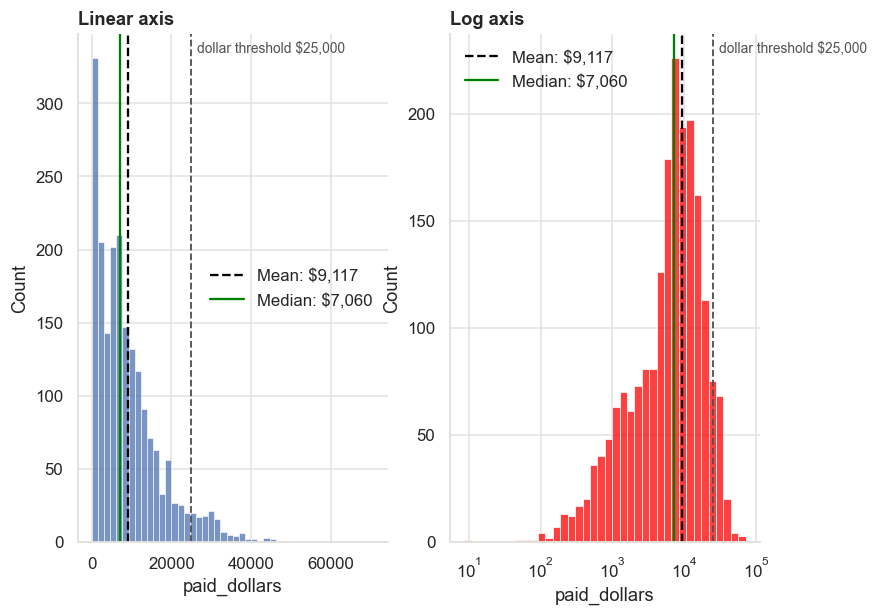

In [9]:
# mean and median values
mean_val = df_merge['paid_dollars'].mean()
median_val = df_merge['paid_dollars'].median()

# two plot areas
fig, axes = plt.subplots(1, 2, figsize=(8, 6))
sns.histplot(data=df_merge, x='paid_dollars',color='#4C72B0', ax=axes[0])
threshold_line(axes[0])
sns.histplot(data=paid_over, x='paid_dollars', color='red' ,log_scale=True ,ax=axes[1])
threshold_line(axes[1])

# drawin the axlines on both panels
for ax in axes:
    ax.axvline(mean_val, color='black', linestyle='--',label=f'Mean: ${mean_val:,.0f}')
    ax.axvline(median_val, color='green', linestyle='-', label=f'Median: ${median_val:,.0f}')
    ax.legend()

# display plot
axes[0].set_title('Linear axis')
axes[1].set_title('Log axis')
plt.show()

- The median should be the typical value for each member. Using the mean would result in a skewed value due to few data points (patients) whose cost of insurance is astronomically high compared to a vast majority of the populace.

### How much spend sits with the top few?

Last week: in real US healthcare, the costliest 5% of people drive about half
of all spending. Check whether your cohort looks like that.

In [10]:
# ---------------------------------------------------------------------------
# TODO 3 — share of total spend held by the top X% of members.
#
# Sort members from most to least expensive. Plot the running share of
# total spend (y) against the share of members counted so far (x). Add a
# dashed diagonal for "everyone costs the same". Then print the share
# held by the top 5%, 10% and 20%.
#
# Docs that will help:
#   - numpy.sort  (it sorts ascending; how do you reverse it?)
#     https://numpy.org/doc/stable/reference/generated/numpy.sort.html
#   - numpy.cumsum
#     https://numpy.org/doc/stable/reference/generated/numpy.cumsum.html
#   - numpy.arange
#     https://numpy.org/doc/stable/reference/generated/numpy.arange.html
#   - Axes.plot  (see the linestyle argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

# your code here

Top 5%: 18.2%
Top 10%: 30.8%
Top 20%: 49.3%


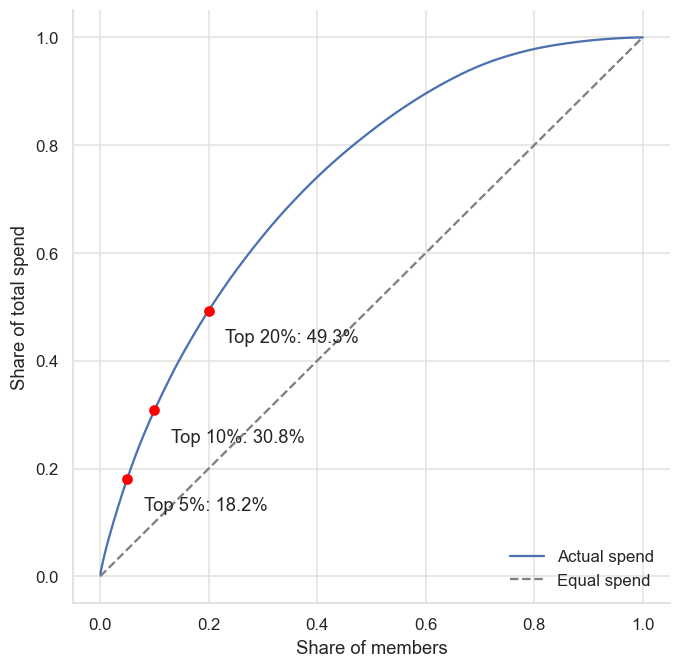

In [11]:
# Sort members by spend
df_sorted = df_merge.sort_values(by='paid_dollars', ascending=False)
# running share (cumulative total / grand total)
Running_share = df_sorted['paid_dollars'].cumsum() / df_sorted['paid_dollars'].sum()
# Share of members counted so far
member_share = np.arange(1, len(df_sorted) + 1) / len(df_sorted)

# plotting a concentration curve
fig, ax = plt.subplots(figsize=(7, 7))

# Main curve and the dashed "everyone costs the same" diagonal
ax.plot(member_share, Running_share.values, color='#4C72B0', label='Actual spend')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Equal spend')

# Marks and labels the top 5%, 10% and 20% points on the curve
for pct in [0.05, 0.10, 0.20]:
    k = int(len(df_sorted) * pct)
    share = Running_share.iloc[k - 1]
    ax.scatter(pct, share, color='red', zorder=5)
    ax.annotate(f'Top {int(pct*100)}%: {share:.1%}',
                xy=(pct, share), xytext=(pct + 0.03, share - 0.06))
    print(f"Top {int(pct*100)}%: {share:.1%}")
    
# display results
ax.set_xlabel('Share of members')
ax.set_ylabel('Share of total spend')
ax.legend(loc='lower right')
plt.show()

Top customer accounts for 39% of the total health spend.

**What you should see.** A curve that bows above the diagonal. The top 20% of
members hold roughly 45–52% of spend.

**Your conclusion**: your top 5% hold ___% of spend. Is that more or less than the ~50% in real life?

> ______

- The top 5% hold about 18% of the total spend. Its less then the expected 50% in real life.

---

## 4. The label is a line someone drew

`is_high_cost` is 1 when a member's plan-paid is over the **dollar threshold**
(`HIGH_COST_THRESHOLD_USD` in `config.py`, $25,000). It is a choice, not a fact
about the member.

In [12]:
# ---------------------------------------------------------------------------
# TODO 4 — your prevalence.
#
# Print how many members are high-cost, and what share of all members that
# is. Then print the accuracy of a "model" that predicts nobody is
# high-cost. (Who would that model get right?)
#
# Docs that will help:
#   - Series.sum
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.sum.html
#   - Series.mean  (the mean of a 0/1 column is a share)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html
# ---------------------------------------------------------------------------

# your code here

In [13]:
threshold = 25000
# Marks high-cost members as those paying above the dollar threshold
is_high = df_merge['paid_dollars'] > threshold

# Count of high-cost members and their share of all members
n_high = is_high.sum()
prevalence = is_high.mean()
print(f"High-cost members: {n_high}")
print(f"Share of all members: {prevalence:.1%}")

# A model that predicts nobody is high-cost is right for every non-high-cost member
baseline_accuracy = 1 - prevalence
print(f"Accuracy of predicting nobody is high-cost: {baseline_accuracy:.1%}")

High-cost members: 121
Share of all members: 6.0%
Accuracy of predicting nobody is high-cost: 94.0%


**What you should see.** A prevalence between 4% and 9%, so predicting nobody
scores 91%–96% accuracy.

**Your conclusion**: a classmate says their model is 94% accurate. Why isn't that impressive here?

> ______

- an accurcy score of 94% is not to be considered as impressive given the fact that high-cost membersa re of a mninoriuty class, meaning that there was a high class imbalance in the data for those who were classified as low cost and those classifeid as high cost with 94% being low cost, so the model would be predicting low cost mmember a majority of the time.

### What if the line were somewhere else?

$25,000 is a choice. In TODO 4 you asked "what share of members cost more than
$25k?" Now ask the same question for other dollar amounts, from $2,500 up to
$60,000, and plot the answers.

Think of the bar for calling someone "tall": set it at 5 feet and nearly
everyone is tall; set it at 7 feet and almost nobody is.

In [14]:
# ---------------------------------------------------------------------------
# TODO 5 — move the line.
#
# Worked example: the share of members who cost more than $5,000.
#
#     paid > 5_000              -> True/False for every member
#     (paid > 5_000).mean()     -> the share that are True (True counts as 1)
#     (paid > 5_000).sum()      -> the NUMBER that are True
#
# Your steps:
#   1. Make a list to hold your answers:   shares = []
#   2. Loop over `lines` (given below). For each one, work out the share of
#      members above it, the same way as the example, and append it.
#   3. Print each line next to its share, so you can read off $10,000.
#   4. Plot `lines` (x) against `shares` (y) with ax.plot, add dots with
#      marker="o", and call threshold_line(ax) to mark $25k.
#   5. Print the NUMBER of members above $50,000.
#
# Docs that will help:
#   - Comparing a Series to a number gives True/False
#     https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing
#   - Python for loops and list.append
#     https://docs.python.org/3/tutorial/controlflow.html#for-statements
#   - Axes.plot  (see the marker argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

lines = [2_500, 5_000, 10_000, 15_000, 20_000, 25_000, 30_000, 40_000, 50_000, 60_000]

# your code here

$2,500: 76.8%
$5,000: 63.4%
$10,000: 34.5%
$15,000: 18.6%
$20,000: 10.0%
$25,000: 6.0%
$30,000: 3.1%
$40,000: 0.5%
$50,000: 0.1%
$60,000: 0.1%


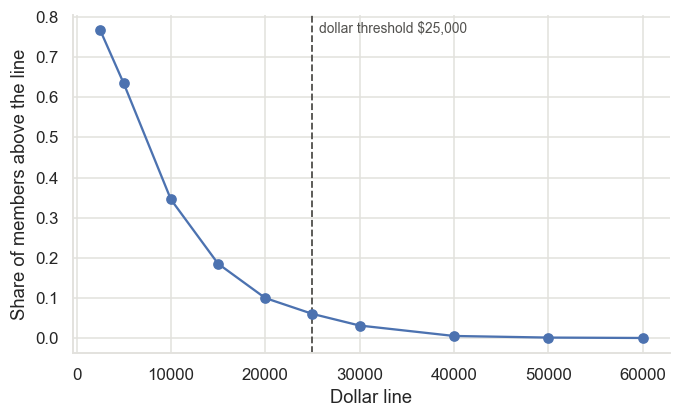

Members above $50,000: 3


In [15]:
# Dollar lines to test as the high-cost cutoff
lines = [2_500, 5_000, 10_000, 15_000, 20_000, 25_000, 30_000, 40_000, 50_000, 60_000]

# Empty list to hold the share of members above each line
shares = []

# For each dollar line, the share of members paying more than it
for line in lines:
    shares.append((paid > line).mean())

# Prints each line next to its share so you can read off $10,000
for line, share in zip(lines, shares):
    print(f"${line:,}: {share:.1%}")

# Plots lines against shares with dots, and marks the $25k line
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lines, shares, marker="o")
threshold_line(ax)
ax.set_xlabel("Dollar line")
ax.set_ylabel("Share of members above the line")
plt.show()

# Prints the number of members above $50,000
print("Members above $50,000:", (paid > 50_000).sum())


**What you should see.** A curve that starts high and drops fast. At $10k,
30–45% of members are over the line; above $50k, only a handful of *members*
(a count, not a percentage).

**Your conclusion**: what goes wrong if the line is set much lower, or much higher?

> ______

- If the line is set much lower a vast majority of the customers/members will be able to  afford the health care costs, leading to a higher demand for services. If the line was higher, only an handful or less would be able to afford the healthcare costs.

---

## 5. Do some groups have more high-cost members?

**The question.** Are older members more likely to be high-cost than younger
ones? Women more than men? One region more than another?

**Step 1: the rate.** For each group, divide the high-cost members by all the
members in that group. 20 high-cost out of 400 members is a rate of 5%.

**Step 2: why a rate on its own can fool you.** High-cost members are rare, so
each group only has a few dozen of them. With numbers that small, luck moves
the rate a lot. Two groups can look different when the gap is just chance.

Think of coin flips: 7 heads in 10 flips doesn't prove a coin is unfair, but
700 heads in 1,000 flips does. The more flips, the more you can trust the
result.

**Step 3: the 95% interval.** This is the range the group's *true* rate
probably sits in, given how many members we have. Fewer members means a wider
range. Both of these are 5%, but we're much surer about the second:

| High-cost / members | Rate | 95% interval |
|---|---|---|
| 5 / 100 | 5% | 2.2% to 11.2% |
| 50 / 1,000 | 5% | 3.8% to 6.5% |

**How to read the plot.** Each group gets one row:

```
            0%        5%        10%
Group A        |----●----|                ● = the group's rate
Group B             |------●------|       |--| = its 95% interval
                     ¦                    ¦ (dashed) = rate for everyone
```

- **The lines overlap:** you can't say the groups differ. The gap could be luck.
- **The lines don't overlap:** the difference is probably real.

Example: Group A is 20 / 400 = 5% (3.3% to 7.6%). Group B is 30 / 400 = 7.5%
(5.3% to 10.5%). B looks higher, but the ranges overlap, so you **can't** claim
a difference.

**What you'll write.** For each variable, one of two sentences:

- "*X* has a higher rate than *Y*, and their intervals don't overlap."
- "No detectable difference at this sample size."

The second one is a complete answer. It does **not** mean "there is no
difference"; it means we don't have enough members to tell.

**Why it matters.** If the data has a real gap between groups, a model trained
on it will learn that gap too. Week 6 asks whether that's fair.

In [16]:
# ---------------------------------------------------------------------------
# TODO 6 — high-cost rate by group, with 95% intervals.
#
# Worked example: count members and high-cost members in each age bucket.
#
#     table = summary.groupby("age_bucket")["is_high_cost"].agg(n="size", positives="sum")
#
#   n         = members in the group
#   positives = high-cost members (is_high_cost is 0/1, so the sum counts the 1s)
#
# Your steps, starting with age_bucket:
#   1. Run the worked example. Then put the buckets in order:
#          table = table.reindex(AGE_ORDER)
#   2. Add a "rate" column: positives divided by n.
#   3. Add "lo" and "hi" columns with the given helper:
#          table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
#   4. print(table), then plot it with the given helper:
#          fig, ax = plt.subplots(figsize=(5, 3))
#          plot_rates(table, ax, "age_bucket")
#   5. Do the same for "sex" and "region". Skip the reindex step; those
#      groups have no natural order.
#
# Docs that will help:
#   - DataFrame.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
#   - Adding a new column from existing ones
#     https://pandas.pydata.org/docs/getting_started/intro_tutorials/05_add_columns.html
#   - Series.reindex
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

# your code here

              n  positives      rate        lo        hi
age_bucket                                              
18-29       283          9  0.031802  0.016820  0.059326
30-39       446         18  0.040359  0.025679  0.062889
40-49       568         32  0.056338  0.040186  0.078451
50-59       518         34  0.065637  0.047347  0.090322
60-64       185         28  0.151351  0.106837  0.210050


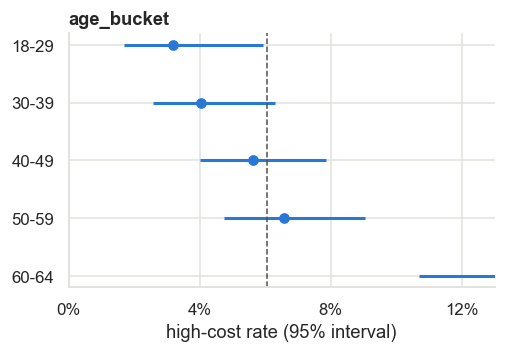

In [17]:
# Counts members and high-cost members in each age bucket
table = summary.groupby("age_bucket")["is_high_cost"].agg(n="size", positives="sum")

# Puts the buckets in their natural order
table = table.reindex(AGE_ORDER)

# Rate = high-cost members divided by all members in the group
table["rate"] = table["positives"] / table["n"]

# Adds the 95% interval bounds using the given helper
table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])

print(table)

# Plots the rates with their intervals
fig, ax = plt.subplots(figsize=(5, 3))
plot_rates(table, ax, "age_bucket")
plt.show()

        n  positives      rate        lo        hi
sex                                               
F     963         65  0.067497  0.053309  0.085123
M    1037         56  0.054002  0.041818  0.069478


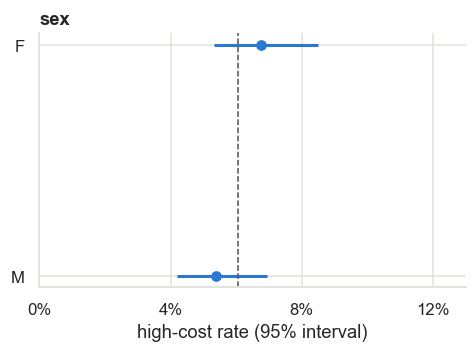

             n  positives      rate        lo        hi
region                                                 
Midwest    413         20  0.048426  0.031564  0.073612
Northeast  416         29  0.069712  0.048973  0.098325
Southeast  417         25  0.059952  0.040934  0.087004
Southwest  379         21  0.055409  0.036523  0.083217
West       375         26  0.069333  0.047751  0.099650


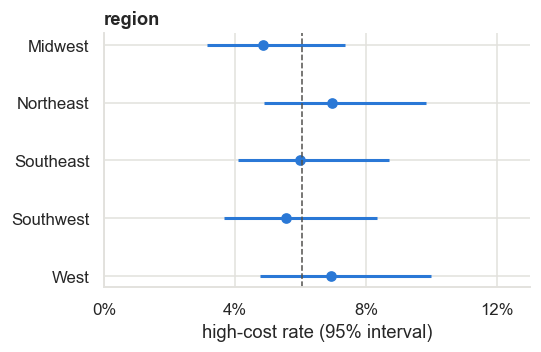

In [18]:
# Sex at birth plot and region
for col in ["sex", "region"]:
    t = summary.groupby(col)["is_high_cost"].agg(n="size", positives="sum")
    t["rate"] = t["positives"] / t["n"]
    t["lo"], t["hi"] = wilson_interval(t["positives"], t["n"])
    print(t)

# display plot
    fig, ax = plt.subplots(figsize=(5, 3))
    plot_rates(t, ax, col)
    plt.show()

**What you should see.** `sex` and `region` rates within a few points of each
other, with intervals that overlap. `age_bucket` usually rises with age, but in
some cohorts even age is too close to call.

**Your conclusion**: which variable, if any, shows a difference you can defend? For the others, write "no detectable difference at this sample size".

> ______

- The variables i can d defend would be the sex. Most females tend to utilize healthcare resoures than their male counterparts, resulting in more hospital visits as such more costly. 

---

## 6. One question for every column

The prediction is made on **January 1**. The label is only known after
**December 31**. So, for each column in `member_summary.csv`:

> **"On the day I need this prediction, do I already know this number?"**

**TODO 7: fill in the last column.** No code. Write *Yes*, *No* or
*Debatable*, and a few words of why. Look at how each column is defined, not at
how well it correlates with the label.

- **Yes:** you'd know it on January 1.
- **No:** it's the outcome, or nearly the same number as the outcome.
- **Debatable:** you'd know a version of it on January 1, but this column was
  measured over the same year as the label.

| Column | What it is | Known on day one? |
|---|---|---|
| `age_bucket` | banded age | No |
| `sex` | recorded sex | Yes |
| `region` | US region | Yes |
| `total_claims` | approved claims in the year | Yes |
| `medical_claims` | of those, non-pharmacy | Yes |
| `pharmacy_claims` | of those, pharmacy | Yes |
| `specialty_drug_fills` | specialty fills in the year | Yes |
| `total_billed_cents` | what providers billed | Debatable |
| `total_allowed_cents` | what the plan allowed | Debatable |
| `total_plan_paid_cents` | what the plan paid | Yes |
| `total_oop_cents` | what the member paid | Yes |
| `unique_diagnosis_codes` | distinct diagnoses seen | Yes |
| `inpatient_claims` | institutional claims | No |
| `has_specialty_drug` | any specialty fill | Yes |
| `is_high_cost` | the label | Yes |

Hint: this data covers one plan year. A real system would use *last* year's
claims to predict *this* year. Which columns could you get from last year?

**Your conclusion**: which row was hardest to decide, and why?

> For me the total_billed_cents and total_allowed_cents are interesting features because they both influence the members results in a similar way and both are important to a predictive model. I would perform a multicollinearity check to determine if they both provide the same value to the target and if so, removing one would be an approopriate measure to take.

`tests/test_leakage.py` fails until Weeks 3–4. That is on purpose, and this
table is what it is about.

---

## 7. Four checks before you trust a figure

In [19]:
# ---------------------------------------------------------------------------
# TODO 8a — missing or structural?
#
# Print the share of blanks in each column of claims that has any. Then
# compare those shares with the share of claims that are pharmacy.
#
# Docs that will help:
#   - DataFrame.isna
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
#   - DataFrame.mean
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html
# ---------------------------------------------------------------------------

# your code here

In [20]:
# Share of blank values in each column
blank_share = claims.isna().mean()
blank_share = blank_share[blank_share > 0].sort_values(ascending=False)
print(blank_share)

drug_name            0.784003
therapeutic_class    0.784003
diagnosis_code       0.215997
procedure_code       0.215997
dtype: float64


In [25]:
# Capital P, matching the real value in claim_type
pharmacy_share = (claims["claim_type"] == "Pharmacy").mean()
print(f"Pharmacy share: {pharmacy_share:.1%}")

Pharmacy share: 21.6%


**What you should see.** No blanks in `members` or `summary`. In `claims`, some
columns blank on about 23% of rows and others on about 77%.

**Your conclusion**: is a blank `diagnosis_code` on a pharmacy claim missing data? What would go wrong if you filled it in?

>No, a blank diagnosis code is not missing data. Pharmacy claims record a drug fill rather than a diagnosis, so the field doesn’t apply. The blank share matches the pharmacy share of claims.

In [22]:
# ---------------------------------------------------------------------------
# TODO 8b — does the money add up?
#
# Every claim should satisfy  plan_paid + out_of_pocket == allowed.
# Print the share of claims where it holds, for each claim_type.
#
# Docs that will help:
#   - Arithmetic and comparisons on columns
#     https://pandas.pydata.org/docs/user_guide/basics.html#flexible-binary-operations
#   - Series.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.groupby.html
# ---------------------------------------------------------------------------

# your code here

In [26]:
# True when plan_paid + out_of_pocket matches allowed (isclose avoids tiny rounding errors)
claims["adds_up"] = np.isclose(
    claims["plan_paid_cents"] + claims["out_of_pocket_cents"], claims["allowed_cents"]
)

# Share of claims where it holds, for each claim type
print(claims.groupby("claim_type")["adds_up"].mean().map("{:.1%}".format))

claim_type
Institutional    91.6%
Pharmacy          0.0%
Professional     91.6%
Name: adds_up, dtype: object


**What you should see.** The identity holds for most medical claims and for
**none** of the pharmacy claims.

**Your conclusion**: the identity fails on some claims. Why does that matter before you build features from these columns?

> The identity fails for all pharmacy claims and for about 8% of medical claims. This matters because the money columns may be defined differently by claim type, and features and the high-cost label are built from them.

In [ ]:
# ---------------------------------------------------------------------------
# TODO 8c — do the counts match?
#
# For each member, does summary's total_claims equal (i) ALL their claims,
# or (ii) only their APPROVED claims? Print the share of members that match
# each. Members with no claims at all should count as 0, not be dropped.
#
# Docs that will help:
#   - DataFrameGroupBy.size
#     https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.size.html
#   - DataFrame.set_index
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html
#   - Series.reindex  (see fill_value)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

# your code here

In [27]:
# Shows the possible values in the status column
print(claims["adjudication_status"].unique())

['approved' 'denied']


In [29]:
s = summary.set_index("member_id")
all_counts = claims.groupby("member_id").size().reindex(s.index, fill_value=0)

approved = claims[claims["adjudication_status"] == "approved"]
approved_counts = approved.groupby("member_id").size().reindex(s.index, fill_value=0)

print(f"Matches ALL claims:      {(s['total_claims'] == all_counts).mean():.1%}")
print(f"Matches APPROVED claims: {(s['total_claims'] == approved_counts).mean():.1%}")

Matches ALL claims:      51.7%
Matches APPROVED claims: 100.0%


**What you should see.** One of the two matches for 100% of members.

**Your conclusion**: which claims does `member_summary.csv` count, and why?

> from the data, member_summary only counts approved claims.

In [ ]:
# ---------------------------------------------------------------------------
# TODO 8d — any time pattern?
#
# Plot the number of claims in each month of service_date, as a line.
# Start the y axis at 0 so small wiggles don't look big.
#
# Docs that will help:
#   - pandas.to_datetime
#     https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
#   - Series.dt.month
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.month.html
#   - Series.value_counts and Series.sort_index
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
#   - Axes.set  (ylim=...)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set.html
# ---------------------------------------------------------------------------

# your code here

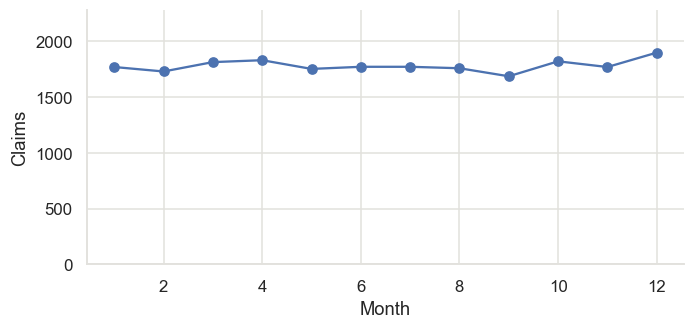

In [30]:
# Converts service_date to dates and counts claims in each calendar month
claims["service_date"] = pd.to_datetime(claims["service_date"])
monthly = claims["service_date"].dt.month.value_counts().sort_index()

# Line plot with the y axis starting at 0 so small wiggles don't look big
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set(ylim=(0, monthly.max() * 1.2), xlabel="Month", ylabel="Claims")
plt.show()

**What you should see.** A roughly flat line.

**Your conclusion**: is there a seasonal pattern? What does that mean for features like "month of first claim"?

> We cant quite say there is seasonality with just one years worth data. As for the month of first claim, i am unsure.

---

## 8. What to carry into Week 3

Fill in your numbers. These are the start of your Week 8 slides.

**The prediction target**

| | |
|---|---|
| Label column | `___is_high_cost___` |
| It is 1 when | `__total_plan_paid____` is over $__25000____ |
| Measured over | ___1 year___ |
| Predicted on | ___Jan 1st___, before __year claims____ |
| Kind of problem | _classification_____ (regression or classification?) |

**Your cohort**

| Finding | Your number |
|---|---|
| Claims rows per member | ___10.7___ |
| Median vs. mean plan-paid | $__7,060____ vs. $___9,117___ |
| Share of spend held by the top 5% | __18.2____ % |
| Prevalence at $25k | __6.0____ % |
| Accuracy of predicting nobody | __94____ % |
| Columns marked Yes / Debatable / No | __11____ / __2____ / __2____ |

## Before you open your PR

- [ ] `pytest tests/test_data.py -v` — nine passing
- [ ] Every `______` is filled in
- [ ] **Kernel → Restart & Run All** works top to bottom
- [ ] The seed printed in section 0 is the one you were assigned
- [ ] Nothing in `data/` is staged — `git status` should not list it

Then commit the notebook, open a PR, and review your partner's. Their seed is
different, so ask how they got their numbers rather than comparing values.